# TP5 · Ejercicio 2 — Autoencoder Variacional (VAE) sobre símbolos matemáticos
**Pregunta guía.** El autoencoder del ej. 1 reconstruye bien pero deja **huecos** en el espacio latente. ¿Qué cambia si obligamos al espacio latente a parecerse a una distribución conocida, $\mathcal{N}(0,I)$, y cómo se mide si una muestra generada “pertenece” al conjunto de datos?

**Bibliografía (del curso).**
- Kingma & Welling (2014), *Auto-Encoding Variational Bayes*, ICLR — `Bibliografía/162970_1312.6114v10.pd.pdf`.
- Doersch (2016), *Tutorial on Variational Autoencoders* — `Bibliografía/1606.05908v3.pdf`.
- Kingma & Welling (2019), *An Introduction to Variational Autoencoders* — `Bibliografía/1906.02691v3.pdf`.
- Blei, Kucukelbir & McAuliffe (2017), *Variational Inference: A Review for Statisticians*, JASA.
- Prince (2023), *Understanding Deep Learning*, **cap. 17 (VAE)**. Goodfellow et al. (2016), §20.10.3. Aggarwal (2023), **§5.10.4**.
- Higgins et al. (2017), *β-VAE*, ICLR.

## 1. Elección del conjunto de datos: **símbolos matemáticos**

El enunciado sugiere emojis; propusimos algo ligado a la matemática. Evaluamos tres opciones:

| Opción | ¿Sirve para un VAE de imágenes? | Decisión |
|---|---|---|
| **MATH** (Hendrycks et al., 2021), problemas de competencia en LaTeX | Es **texto**; un VAE sobre secuencias necesita tokenización y decodificador autorregresivo: otro tema (y sin librerías, otro proyecto) | Descartado como dato; sí lo usamos como *motivación* |
| Fórmulas completas renderizadas | Demasiada variabilidad y resolución para una MLP numpy en 16×16 | Descartado |
| **Símbolos y operadores** (+, −, ×, ÷, ≤, ∑, ∫, ∂, ∇, √, ∞, π, λ…) rasterizados en varias tipografías | Pocas clases bien definidas, resolución 16×16, estilos como **factor de variación continuo**; cualquier equipo puede regenerarlo | **Elegido** |

**Dataset.** 39 símbolos × 8 estilos tipográficos (DejaVu Sans/Serif/Mono, normal, negrita, cursiva) × 9 desplazamientos de ±1 px = **2808 imágenes** de 16×16, en $[0,1]$. Las fuentes DejaVu viajan con `matplotlib`, de modo que el dataset es **reproducible** sin descargar nada. **Partición por estilo:** se *retienen* dos estilos completos (`DejaVu Serif` y `DejaVu Sans Mono`) como validación; así medimos si el modelo **generaliza a tipografías no vistas**, no sólo si memoriza.

Hay un atractivo conceptual: los símbolos comparten estructura (≤ y ≥ son espejos; + y × son rotaciones; ∑ y ∏ comparten trazos), entonces un espacio latente bien formado debería **mezclarlos de forma coherente**, y sus interpolaciones pueden mostrar relaciones matemáticas.

imágenes: (2808, 256) | entrenamiento: 2106 | validación (estilos no vistos): 702


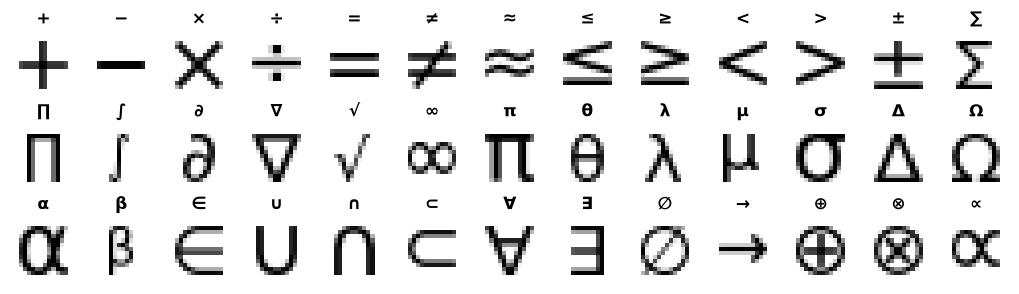

In [1]:
import sys, json, pickle, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ))
from deep import Autoencoder, VAE, pixel_errors, gradient_check, gradient_check_vae
from datos import cargar_font3, ruido_sal_pimienta, SIMBOLOS, generar_simbolos
from experimentos import *
from graficos import *
cfg = cargar_config()
RES = RAIZ / "results"
np.random.seed(cfg["semilla_global"])

D = datos_simbolos(cfg)
X, lab, sty = D["X"], D["lab"], D["sty"]
print("imágenes:", X.shape, "| entrenamiento:", D["tr"].sum(), "| validación (estilos no vistos):", D["te"].sum())
sel = [np.where((sty == 0) & (lab == i) & (D["dsp"] == 4))[0][0] for i in range(len(SIMBOLOS))]
fig = mostrar_imagenes(X[sel], (16, 16), SIMBOLOS, ncols=13, tam=0.9, ax_title_size=11); plt.show()

## 2. Marco teórico: del autoencoder al VAE

### 2.1 Modelo generativo y el problema de inferencia
Suponemos que cada imagen $x$ se genera así: $z\sim p(z)=\mathcal{N}(0,I)$, luego $x\sim p_\phi(x\mid z)=\mathrm{Bernoulli}(g_\phi(z))$. Para entrenar queremos maximizar $\log p_\phi(x)=\log\int p_\phi(x\mid z)p(z)\,dz$, **intratable** (integral sobre una red neuronal). La posterior $p(z\mid x)$ tampoco se conoce. La *inferencia variacional* (Blei et al., 2017) la reemplaza por una familia tratable $q_\theta(z\mid x)=\mathcal{N}(\mu_\theta(x),\mathrm{diag}\,\sigma^2_\theta(x))$ cuyos parámetros salen del **codificador**.

### 2.2 La cota inferior (ELBO)
Para cualquier $q$,

$$\log p_\phi(x)=\underbrace{\mathbb{E}_{q}[\log p_\phi(x\mid z)]-\mathrm{KL}\big(q_\theta(z\mid x)\,\|\,p(z)\big)}_{\mathrm{ELBO}(x)}+\underbrace{\mathrm{KL}\big(q_\theta(z\mid x)\,\|\,p_\phi(z\mid x)\big)}_{\ge 0}.$$

Maximizar el ELBO **a la vez** (i) mejora la reconstrucción y (ii) acerca $q$ a la posterior verdadera. La pérdida a minimizar es $-\mathrm{ELBO}$: *reconstrucción (BCE) + regularizador KL*. **Ese término KL es lo que le da forma al espacio latente**: empuja cada $q(z\mid x)$ hacia $\mathcal{N}(0,I)$, de modo que el prior queda cubierto sin huecos y **muestrear $z\sim\mathcal{N}(0,I)$ y decodificar produce imágenes plausibles**.

### 2.3 KL cerrada y truco de reparametrización
Para gaussianas diagonales:

$$\mathrm{KL}\big(\mathcal{N}(\mu,\sigma^2)\,\|\,\mathcal{N}(0,I)\big)=\tfrac12\sum_{j=1}^{d}\big(\mu_j^2+\sigma_j^2-\log\sigma_j^2-1\big).$$

Para derivar respecto de $\theta$ a través de un muestreo se usa $z=\mu+\sigma\odot\varepsilon,\ \varepsilon\sim\mathcal{N}(0,I)$: la aleatoriedad pasa a $\varepsilon$ (independiente de $\theta$) y el gradiente fluye por $\mu$ y $\sigma$. Los gradientes que implementa `VAE.loss_grads` son

$$\frac{\partial\mathcal{L}}{\partial\mu}=\frac{\partial\mathcal{L}_{rec}}{\partial z}+\beta\mu,\qquad \frac{\partial\mathcal{L}}{\partial\log\sigma^2}=\frac{\partial\mathcal{L}_{rec}}{\partial z}\cdot\tfrac12\sigma\varepsilon+\tfrac{\beta}{2}(\sigma^2-1),$$

validados con diferencias finitas en el notebook del ejercicio 1 (error relativo $\sim10^{-8}$).

### 2.4 El factor $\beta$ (Higgins et al., 2017)
$\mathcal{L}_\beta=\mathcal{L}_{rec}+\beta\,\mathrm{KL}$. Con $\beta=1$ es el ELBO exacto; $\beta=0$ **es el autoencoder determinístico** (el KL no actúa, la varianza colapsa); $\beta>1$ prioriza un espacio latente ordenado a costa de reconstrucciones más borrosas. Es nuestro *experimento de ablación* natural: aísla el efecto del término variacional.

### 2.5 Cómo juzgar que una muestra "pertenece" al conjunto (consigna 2c)
El enunciado pide una muestra que *"ustedes puedan juzgar"* que pertenece al conjunto. Además del juicio visual usamos **medidas objetivas** construidas con un **clasificador propio** de los 39 símbolos (MLP con softmax, entrenado con los estilos de entrenamiento; exactitud en estilos **no vistos**: ver §3):

1. **Distancia de Fréchet** (la métrica del FID, Heusel et al. 2017) entre los rasgos (capa oculta del clasificador) de 2000 muestras $z\sim\mathcal{N}(0,I)$ decodificadas y los de imágenes **reales de estilos no vistos**: $\;\|m_1-m_2\|^2+\mathrm{tr}(S_1+S_2-2(S_1S_2)^{1/2})$. Mide a la vez calidad y diversidad; menor es mejor. **Referencia (piso):** la misma distancia entre imágenes reales de entrenamiento y reales no vistas ($\approx14$): si un generador llega a ese valor, sus muestras son estadísticamente tan parecidas a las reales como lo son entre sí dos conjuntos reales.
2. **Distancia al vecino más cercano** del entrenamiento: una muestra con distancia mucho menor que la típica real sería una **copia** (no es una muestra nueva).

> **Trampa que evitamos.** La *confianza* del clasificador **no** sirve como medida de plausibilidad: los clasificadores son sobreconfiados fuera de distribución. En nuestro experimento, el autoencoder determinístico ($\beta=0$) obtiene *más* muestras con confianza $\ge0{,}9$ (37–47 %) que el VAE ($\beta=1$: 11–29 %) aunque sus imágenes son basura visible (cuadros negros, texturas). Un primer análisis con esa métrica daba la conclusión opuesta a la correcta; lo corregimos con la distancia de Fréchet.

## 3. Ablación sobre $\beta$ y sobre el tamaño del latente (3 semillas por celda, validación en estilos no vistos)
Variamos $\beta\in\{0;0{,}25;1;4\}$ y la dimensión latente $d\in\{2;8;16\}$ (en $d=2$ se puede *ver* el espacio; en $d=16$ se puede *dibujar bien*). Semillas 0–2, 150 épocas, Adam.

In [2]:
db = pd.concat([pd.DataFrame(json.loads((RES / f"ej2_beta_d{d}.json").read_text())) for d in (2, 8, 16)])
proba, acc = entrenar_clasificador(D, cfg)
print(f"Juez: exactitud del clasificador en estilos NO vistos = {acc:.4f}")
cols = ["val_elbo", "kl", "err_px_test", "fd", "reconocibles"]
tabla = db.groupby(["latent", "beta"])[cols].mean().round(2); tabla

Juez: exactitud del clasificador en estilos NO vistos = 0.9986


val_elbo      kl  err_px_test      fd  reconocibles
latent beta                                                     
2      0.00     93.81   29.12        30.33  156.39          0.37
       0.25     72.38    7.93        28.52   85.30          0.18
       1.00     71.48    5.63        29.27   33.57          0.11
       4.00     78.97    2.86        35.50   54.24          0.01
8      0.00    118.64   79.46        12.05  403.96          0.43
       0.25     59.81   19.90        11.86   44.11          0.32
       1.00     57.48   12.59        13.26   14.38          0.29
       4.00     73.01    4.23        26.85   36.82          0.06
16     0.00    138.51  103.97         8.97  358.58          0.47
       0.25     64.69   28.12         9.16   14.25          0.28
       1.00     57.68   13.51        12.51   13.52          0.27
       4.00     74.24    3.74        28.04   40.07          0.05

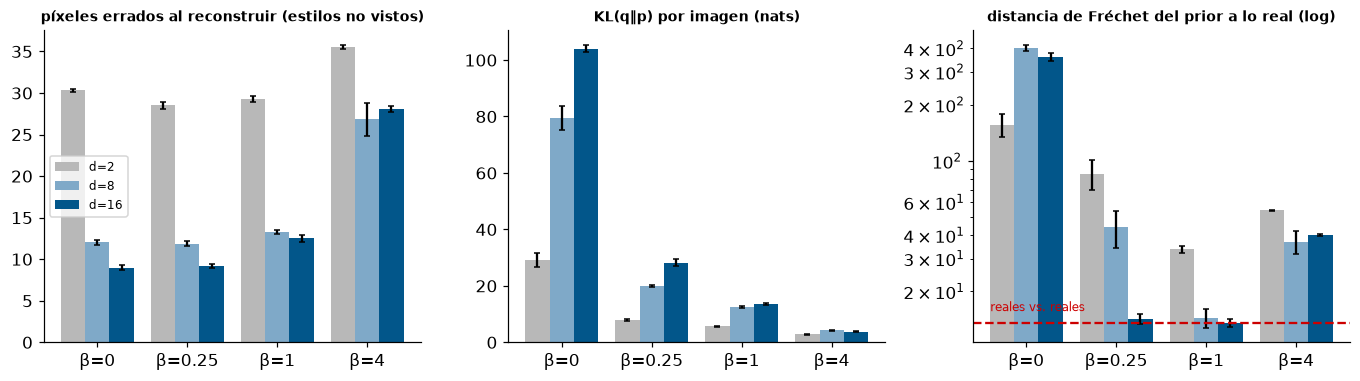

In [3]:
fd_ref = db.fd_ref.mean(); colD = {2: GRIS, 8: "#7FA9C8", 16: AZUL}; betas = sorted(db.beta.unique())
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.6))
for ax, (cc, tit, log) in zip(axs, [("err_px_test", "píxeles errados al reconstruir (estilos no vistos)", False),
                                    ("kl", "KL(q‖p) por imagen (nats)", False),
                                    ("fd", "distancia de Fréchet del prior a lo real (log)", True)]):
    for k, dd in enumerate((2, 8, 16)):
        g = db[db.latent == dd].groupby("beta")[cc]
        ax.bar(np.arange(len(betas)) + (k - 1) * .27, g.mean().values, .27, yerr=g.std().values, color=colD[dd], capsize=2, label=f"d={dd}")
    ax.set_xticks(range(len(betas))); ax.set_xticklabels([f"β={b:g}" for b in betas]); ax.set_title(tit, fontsize=9)
    if log: ax.set_yscale("log"); ax.axhline(fd_ref, color=ROJO, ls="--"); ax.text(-.4, fd_ref * 1.15, "reales vs. reales", color=ROJO, fontsize=8)
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Lectura (medias de 3 semillas; tabla de arriba y `results/ej2_beta_d*.json`).**
1. **Reconstrucción.** Aumentar $d$ de 2 a 8 baja el error de reconstrucción en estilos no vistos de ~29 a ~13 píxeles (de 256); de 8 a 16 ya no mejora con $\beta=1$. $\beta=4$ la empeora mucho (ordenar el espacio cuesta información).
2. **KL.** $\beta=0$ no regulariza: el KL (que se mide aunque no se optimice) crece con $d$ (29 → 104 nats). Con $\beta\ge1$ el KL queda en 3–14 nats: el codificador **ya no puede desparramar** los códigos.
3. **Calidad generativa (distancia de Fréchet).** El efecto del KL es enorme: con $d=16$, el AE ($\beta=0$) queda muy lejos de las imágenes reales y el VAE ($\beta=1$) **al nivel del piso** de comparar dos conjuntos reales (ver tabla; modelos finales con semilla 0: ~13 frente a ~380, piso ~14). Con $d=2$ el VAE llega a ~32 (el cuello de botella limita la nitidez); con $d=8$, a ~15.
4. **$\beta=1$ es el punto de equilibrio**: $\beta=0{,}25$ reconstruye un poco mejor pero muestrea peor; $\beta=4$ sobre-regulariza (muestras borrosas y pocas clases distintas).

## 4. Modelos finales: $d=2$ para *ver* el espacio, $d=16$ para *generar*

    epoch   loss    rec    kl  val_elbo
9     135  74.78  69.34  5.44     72.64
10    150  72.66  66.98  5.68     71.70


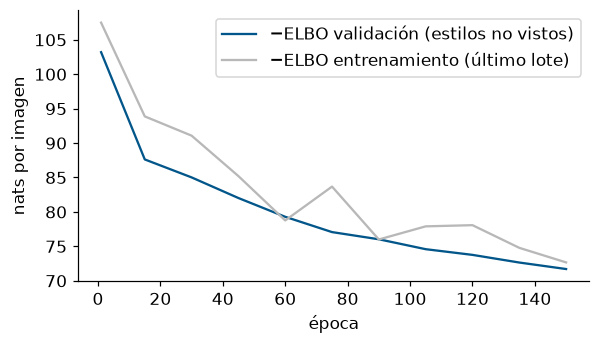

In [4]:
c = cfg["ej2"]
v, hist = entrenar_vae(D, cfg, 1.0, c["semilla_final"], latent=2)          # VAE d=2
v0, _ = entrenar_vae(D, cfg, 0.0, c["semilla_final"], latent=2)            # AE (β=0) d=2
vG, _ = entrenar_vae(D, cfg, 1.0, c["semilla_final"], latent=16)           # VAE d=16
v0G, _ = entrenar_vae(D, cfg, 0.0, c["semilla_final"], latent=16)          # AE (β=0) d=16
h = pd.DataFrame(hist); print(h.tail(2).round(2))
fig, ax = plt.subplots(figsize=(6, 3.2)); ax.plot(h.epoch, h.val_elbo, color=AZUL, label="−ELBO validación (estilos no vistos)"); ax.plot(h.epoch, h.loss, color=GRIS, label="−ELBO entrenamiento (último lote)")
ax.set_xlabel("época"); ax.set_ylabel("nats por imagen"); ax.legend(); plt.show()

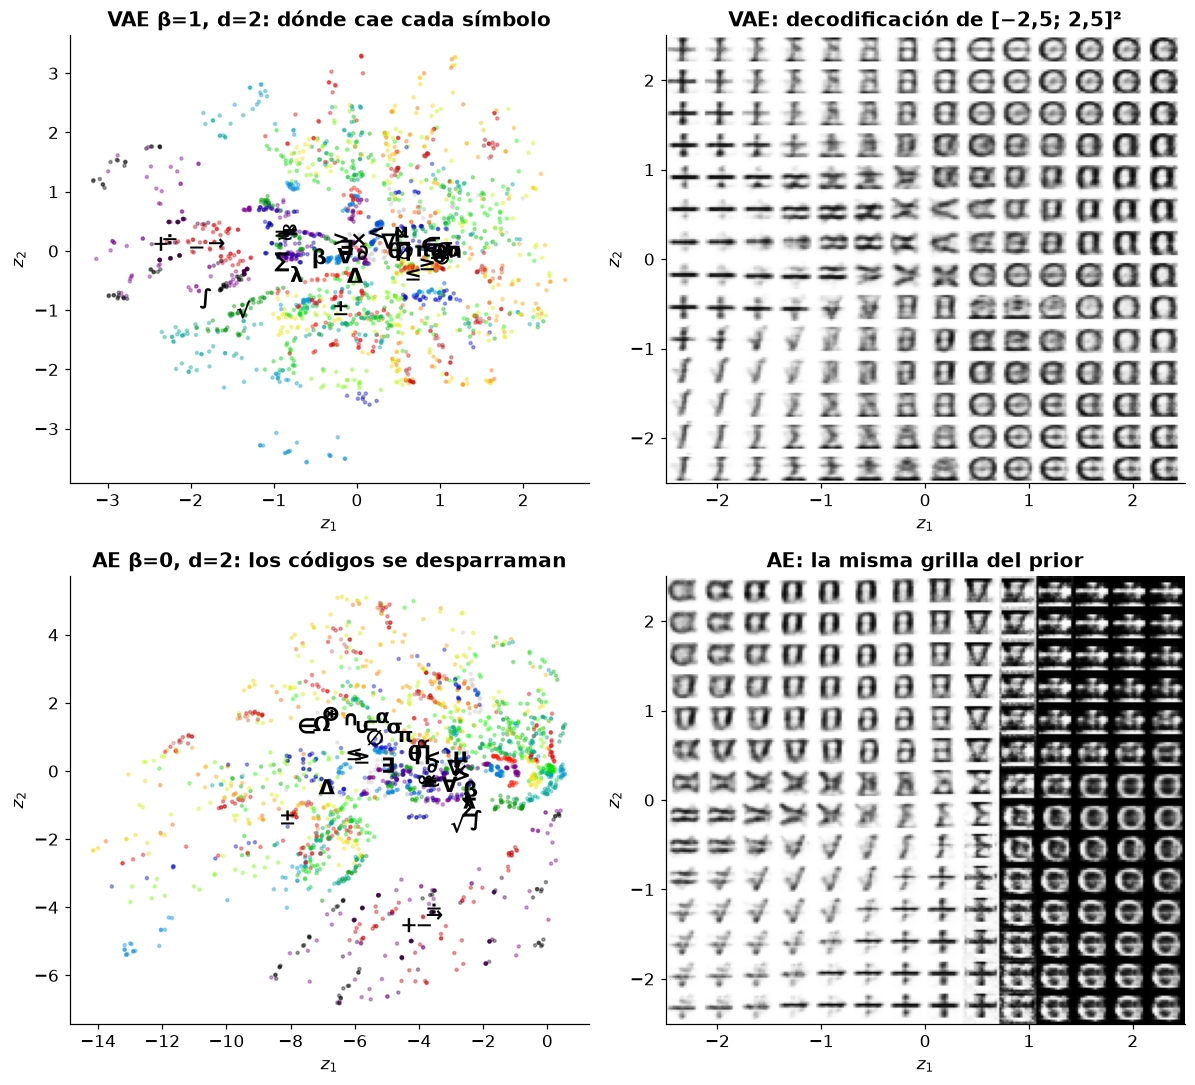

In [5]:
Xtr = X[D["tr"]]; ltr = lab[D["tr"]]
mu, lv = v.encode(Xtr); mu0, _ = v0.encode(Xtr)
def mapa(ax, M, tit):
    ax.scatter(M[:, 0], M[:, 1], c=ltr, cmap="nipy_spectral", s=4, alpha=.35)
    for k in range(len(SIMBOLOS)):
        m = M[ltr == k].mean(0); ax.text(m[0], m[1], SIMBOLOS[k], fontsize=14, ha="center", va="center", fontweight="bold")
    ax.set_title(tit); ax.set_xlabel("$z_1$"); ax.set_ylabel("$z_2$")
fig, axs = plt.subplots(2, 2, figsize=(11, 10))
mapa(axs[0, 0], mu, "VAE β=1, d=2: dónde cae cada símbolo"); grilla_decodificada(v.decode, (16, 16), lim=2.5, n=14, ax=axs[0, 1]); axs[0, 1].set_title("VAE: decodificación de [−2,5; 2,5]²")
mapa(axs[1, 0], mu0, "AE β=0, d=2: los códigos se desparraman"); grilla_decodificada(v0.decode, (16, 16), lim=2.5, n=14, ax=axs[1, 1]); axs[1, 1].set_title("AE: la misma grilla del prior")
plt.tight_layout(); plt.show()

**Qué mirar.** (i) El VAE usa el entorno de $\mathcal{N}(0,I)$ con códigos compactos (desvío de $\mu$ ≈ 1,2); el AE los dispersa (desvío ≈ 3,7). (ii) En $d=2$ la separación entre símbolos es **débil**: 39 clases × estilos no caben con nitidez en 2 dimensiones, y la grilla muestra mezclas borrosas (símbolos horizontales a la izquierda, formas cerradas a la derecha). (iii) Por eso $d=2$ sirve para *ver* la geometría y no para generar bien.

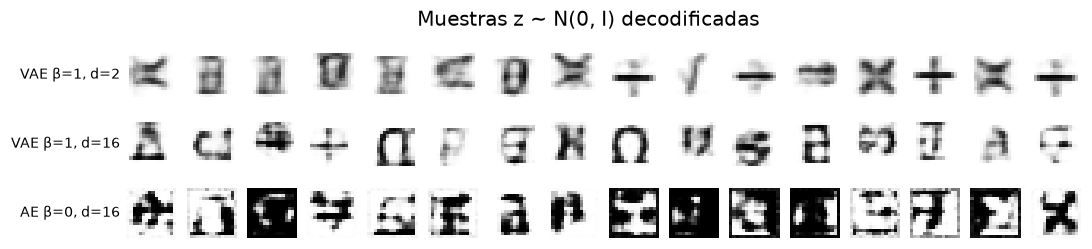

VAE d=16: Fréchet    13.3 (piso 14.2) | confianza>=0,9: 0.26 | copias: 0.000
AE  d=16: Fréchet   377.5 (piso 14.2) | confianza>=0,9: 0.45 | copias: 0.000


VAE d=2: Fréchet    32.4 (piso 14.2) | confianza>=0,9: 0.12 | copias: 0.000
AE  d=2: Fréchet   148.0 (piso 14.2) | confianza>=0,9: 0.41 | copias: 0.000


In [6]:
rng = np.random.default_rng(7); Zp2, ZpG = rng.standard_normal((16, 2)), rng.standard_normal((16, 16))
fig = fila_comparada([v.decode(Zp2), vG.decode(ZpG), v0G.decode(ZpG)], ["VAE β=1, d=2", "VAE β=1, d=16", "AE β=0, d=16"], (16, 16), tam=.7)
plt.suptitle("Muestras z ~ N(0, I) decodificadas", y=1.02); plt.show()
for nom, m in [("VAE d=16", vG), ("AE  d=16", v0G), ("VAE d=2", v), ("AE  d=2", v0)]:
    q = calidad_generativa(m, D, proba=proba); print(f"{nom}: Fréchet {q['fd']:7.1f} (piso {q['fd_ref']:.1f}) | confianza>=0,9: {q['reconocibles']:.2f} | copias: {q['frac_copia']:.3f}")

### 4.1 Generación de una muestra nueva (consigna 2c)
Entre 1500 muestras del prior ($d=16$) se retienen las que cumplen simultáneamente: (i) **no son copias** (distancia al vecino más cercano $>0{,}5\times$ la mediana real) y (ii) son reconocidas por el juez con confianza $\ge0{,}9$. De esas se muestran las **más nítidas** (menor distancia a un dato), una por clase, junto a su **vecino real más cercano** para evidenciar que no son el mismo símbolo.

382 de 1500 muestras del prior son reconocibles y no copias


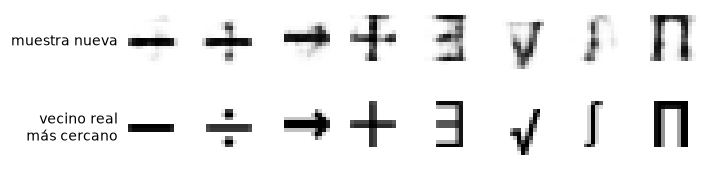

símbolo que reconoce el juez: ['−', '÷', '→', '+', '∃', '√', '∫', '∏']


In [7]:
Zc = rng.standard_normal((1500, 16)); Gc = vG.decode(Zc); dn = dist_vecino(Gc, Xtr); P = proba(Gc)
reales = dist_vecino(D["X"][D["te"]], Xtr)
ok = np.where((P.max(1) >= 0.9) & (dn > 0.5 * np.median(reales)))[0]
print(f"{len(ok)} de 1500 muestras del prior son reconocibles y no copias")
elegidos = []
for i in ok[np.argsort(dn[ok])]:
    if P[i].argmax() not in [P[j].argmax() for j in elegidos]: elegidos.append(i)
    if len(elegidos) == 8: break
vec = [np.argmin(((Xtr - Gc[i]) ** 2).sum(1)) for i in elegidos]
fig = fila_comparada([Gc[elegidos], Xtr[vec]], ["muestra nueva", "vecino real\nmás cercano"], (16, 16), tam=.85); plt.show()
print("símbolo que reconoce el juez:", [SIMBOLOS[P[i].argmax()] for i in elegidos])

### 4.2 Interpolaciones: ¿el espacio latente captura relaciones entre símbolos?
Interpolamos linealmente entre los códigos medios (en $d=16$) de dos símbolos. Si el espacio latente es coherente, el camino pasa por imágenes *intermedias plausibles*, no por ruido.

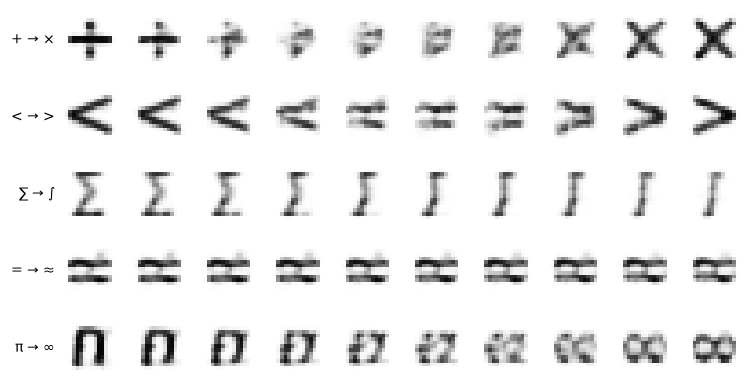

In [8]:
muG, _ = vG.encode(Xtr)
cent = {s: muG[ltr == i].mean(0) for i, s in enumerate(SIMBOLOS)}
pares = [("+", "×"), ("<", ">"), ("∑", "∫"), ("=", "≈"), ("π", "∞")]
filas = [vG.decode(np.array([(1 - t) * cent[a] + t * cent[b] for t in np.linspace(0, 1, 10)])) for a, b in pares]
fig = fila_comparada(filas, [f"{a} → {b}" for a, b in pares], (16, 16), tam=.8); plt.show()

## 5. Conclusiones y limitaciones
1. **El término KL es lo que vuelve muestreable al espacio latente.** Con $d=16$ y $\beta=1$ las muestras del prior quedan al nivel del piso real en distancia de Fréchet (~13 frente a ~14); el autoencoder determinístico, con la misma arquitectura y datos, queda ~30 veces peor (~380). El costo es reconstruir algo peor que con $\beta=0$.
2. **Los símbolos se ordenan sin etiquetas**, pero con $d=2$ la separación es débil: ese espacio sirve para *visualizar*, no para generar.
3. **La métrica importa.** La confianza del clasificador y la distancia de píxeles al vecino más cercano daban conclusiones engañosas (premian lo borroso o lo sobreconfiado); la distancia de Fréchet en el espacio de rasgos del juez, con un piso real como referencia, fue la que resolvió la comparación.
4. **Generalización a estilos no vistos:** el VAE reconstruye tipografías no vistas con ~13 píxeles errados de 256 ($d\ge8$), pero con 6 estilos de entrenamiento no cubre toda la variación tipográfica.
5. **Interpolar** entre símbolos produce intermedios plausibles cuando son parientes morfológicos (+/×, </>): es parecido visual, no significado matemático.
6. **Limitaciones.** MLP sobre 16×16 (no convolucional); dataset sintético (fuentes) y no manuscrito; verosimilitud factorizada por píxel que produce imágenes algo borrosas (Doersch 2016, §2.1); 3 semillas por celda; el juez es un clasificador propio sin garantías fuera de distribución (por eso usamos el piso real). **Extensión natural:** VAE sobre **tokens de LaTeX** del conjunto MATH (Hendrycks et al., 2021) con decodificador recurrente, para generar ecuaciones; requiere un modelo de secuencias.